# Tugas: Clustering dengan DBSCAN, BIRCH, dan EM (Gaussian Mixture Model)

| Nama | NRP |
|------|-----|
| Sulaiman Faiz Tsaqib | 5054251048 |

## Deskripsi Tugas

Pada tugas ini, kalian akan melakukan clustering pada data pelanggan pusat perbelanjaan (*Mall Customer Segmentation*). Kalian akan membandingkan tiga pendekatan clustering:

1. **DBSCAN**, yang membentuk cluster berdasarkan kepadatan data dan dapat menandai data sebagai noise.
2. **BIRCH**, yang merangkum data ke dalam struktur pohon untuk membentuk subcluster.
3. **Expectation-Maximization (EM)** menggunakan **Gaussian Mixture Model (GMM)**, yang memodelkan data sebagai campuran beberapa distribusi probabilitas.

Dataset: [Mall Customer Segmentation Data di Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data).

Setiap baris mewakili satu pelanggan. Pada tugas ini, gunakan dua fitur agar hasilnya mudah divisualisasikan:
- `Annual Income (k$)`: pendapatan tahunan dalam ribuan dolar.
- `Spending Score (1-100)`: skor pengeluaran pelanggan.

**Penting:** `CustomerID` hanya merupakan identitas pelanggan, sehingga tidak digunakan sebagai fitur clustering. Kolom `Gender` juga tidak digunakan dalam eksperimen utama agar fokus tetap pada dua fitur numerik. Kolom tersebut boleh digunakan untuk interpretasi tambahan setelah model selesai, bukan sebagai input model.

## Tujuan Pembelajaran

- Melakukan eksplorasi dan preprocessing data sederhana.
- Memahami mengapa feature scaling diperlukan.
- Menjalankan DBSCAN, BIRCH, dan GMM dengan EM.
- Memahami parameter utama dan karakteristik setiap algoritma.
- Membandingkan hasil clustering menggunakan visualisasi dan metrik evaluasi internal.

## Persiapan Dataset

Unduh file CSV dari halaman Kaggle di atas. Letakkan file `Mall_Customers.csv` di folder yang sama dengan notebook ini. Nama file biasanya `Mall_Customers.csv`.

Langkah pengerjaan:
1. Persiapan dataset dan eksplorasi awal.
2. Preprocessing dan feature scaling.
3. Eksperimen DBSCAN.
4. Eksperimen BIRCH.
5. Eksperimen EM menggunakan Gaussian Mixture Model.
6. Evaluasi dan perbandingan model.
7. Analisis serta kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan:
# pandas, numpy, matplotlib, seaborn
# StandardScaler dari sklearn.preprocessing
# DBSCAN dari sklearn.cluster
# Birch dari sklearn.cluster
# GaussianMixture dari sklearn.mixture
# silhouette_score, davies_bouldin_score, calinski_harabasz_score dari sklearn.metrics
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, Birch
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Muat Mall_Customers.csv ke dalam DataFrame bernama df.
# Jika file tidak ditemukan, periksa lokasi file dan nama file.
# Tampilkan 5 baris pertama, jumlah baris/kolom, tipe data, statistik deskriptif,
# jumlah missing value, dan jumlah baris duplikat.
df = pd.read_csv('Mall_Customers.csv')
display(df.head())
print(df.shape)
print(df.dtypes)
display(df.describe())
print(df.isnull().sum())
print('Duplikat:', df.duplicated().sum())

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


(200, 5)
CustomerID                int64
Gender                      str
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64
Duplikat: 0


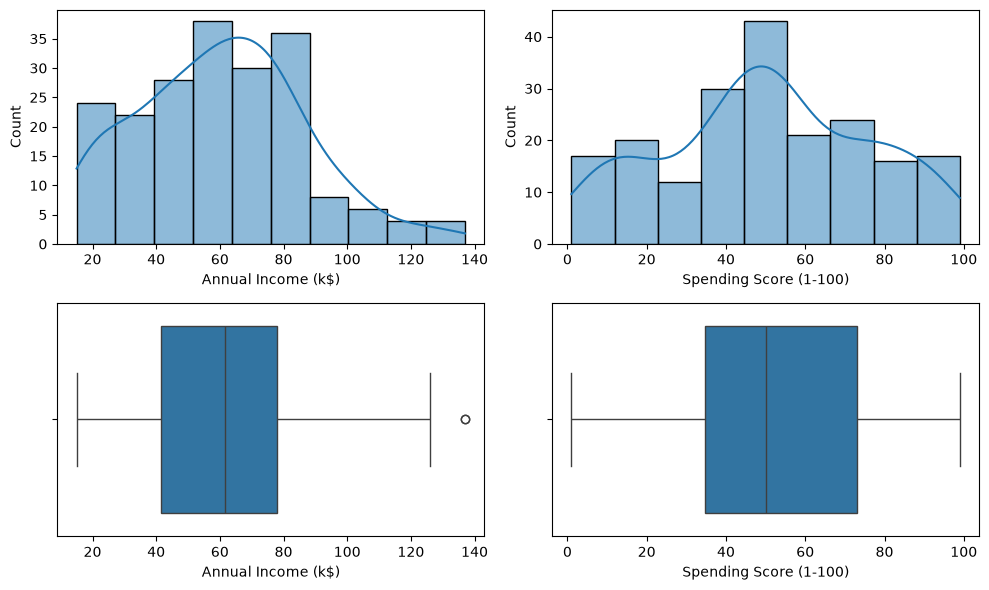

In [3]:
# Tampilkan distribusi Annual Income (k$) dan Spending Score (1-100)
# menggunakan histogram dan/atau boxplot.
# Amati rentang, bentuk distribusi, dan kemungkinan outlier.
cols = ['Annual Income (k$)', 'Spending Score (1-100)']
fig, ax = plt.subplots(2, 2, figsize=(10, 6))
for i, c in enumerate(cols):
    sns.histplot(df[c], kde=True, ax=ax[0, i])
    sns.boxplot(x=df[c], ax=ax[1, i])
plt.tight_layout()
plt.show()

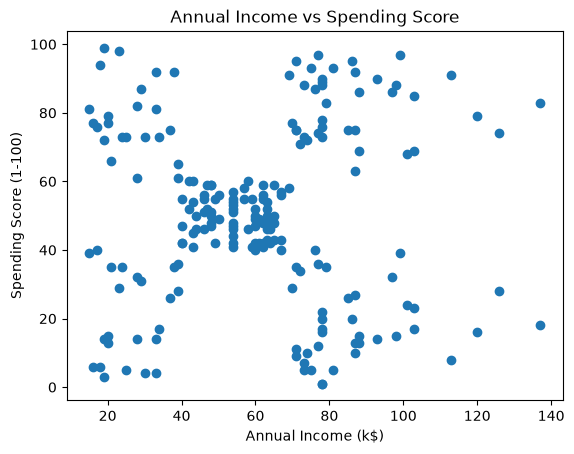

In [4]:
# Buat scatter plot dari Annual Income (k$) terhadap Spending Score (1-100).
# Jangan warnai berdasarkan label apa pun terlebih dahulu.
# Amati apakah terlihat kelompok-kelompok yang terpisah.
plt.scatter(df[cols[0]], df[cols[1]])
plt.xlabel(cols[0])
plt.ylabel(cols[1])
plt.title('Annual Income vs Spending Score')
plt.show()

## Pertanyaan EDA

Tuliskan pengamatan singkat:
- Apakah ada missing value atau baris duplikat?
- Bagaimana rentang pendapatan dan spending score?
- Apakah kedua fitur tampak memiliki kelompok yang terpisah?

**Jawaban:**
- Tidak ada missing value maupun baris duplikat (200 baris, 5 kolom).
- Annual Income berkisar 15–137 k$ (sedikit miring ke kanan, ada outlier di ~137). Spending Score berkisar 1–99 dan relatif simetris.
- Ya, pada scatter plot terlihat sekitar 5 kelompok: satu kelompok padat di tengah dan empat kelompok di sudut-sudutnya.

# 2. Preprocessing

In [5]:
# Periksa dan tangani missing value serta baris duplikat jika ditemukan.
# Karena CustomerID adalah identitas, jangan masukkan kolom tersebut ke fitur clustering.
# Pilih dua fitur numerik:
#   Annual Income (k$)
#   Spending Score (1-100)
# Simpan dalam DataFrame X.
df = df.dropna().drop_duplicates()
X = df[cols]

In [6]:
# Lakukan feature scaling menggunakan StandardScaler.
# Simpan hasilnya sebagai X_scaled.
# Ubah hasil scaling menjadi DataFrame agar nama kolom tetap terlihat.
# Tampilkan beberapa baris X_scaled dan statistik deskriptifnya.
X_scaled = pd.DataFrame(StandardScaler().fit_transform(X), columns=cols)
display(X_scaled.head())
display(X_scaled.describe())

,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


,Annual Income (k$),Spending Score (1-100)
count,2.000000e+02,2.000000e+02
mean,-2.131628e-16,-1.465494e-16
std,1.002509e+00,1.002509e+00
min,-1.738999e+00,-1.910021e+00
25%,-7.275093e-01,-5.997931e-01
50%,3.587926e-02,-7.764312e-03
75%,6.656748e-01,8.851316e-01
max,2.917671e+00,1.894492e+00


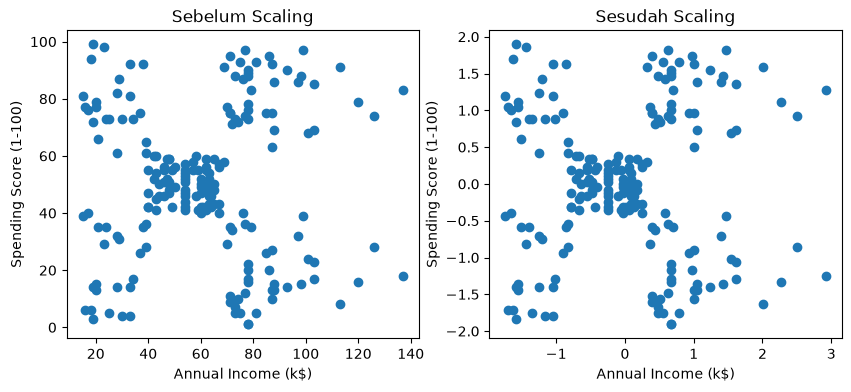

In [7]:
# Buat scatter plot sebelum dan sesudah scaling.
# Jelaskan mengapa scaling penting, terutama ketika algoritma menggunakan jarak
# atau mengasumsikan skala fitur yang sebanding.
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(X[cols[0]], X[cols[1]])
ax[0].set_title('Sebelum Scaling')
ax[1].scatter(X_scaled[cols[0]], X_scaled[cols[1]])
ax[1].set_title('Sesudah Scaling')
for a in ax:
    a.set_xlabel(cols[0])
    a.set_ylabel(cols[1])
plt.show()

**Fitur yang digunakan:** `Annual Income (k$)` dan `Spending Score (1-100)`.

Tuliskan alasan pemilihan kedua fitur tersebut dan jelaskan mengapa `CustomerID` tidak digunakan.

**Jawaban:** Kedua fitur bersifat numerik, relevan untuk segmentasi perilaku belanja (kemampuan vs kebiasaan belanja), dan dapat divisualisasikan dalam 2D. `CustomerID` hanya nomor urut identitas tanpa makna perilaku; jika dipakai, jarak antar-pelanggan akan dipengaruhi nomor urut sehingga cluster menjadi tidak bermakna.

# 3. Eksperimen DBSCAN

DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*) membentuk cluster dari kumpulan titik yang padat. Titik yang tidak memenuhi kepadatan minimum dapat diberi label `-1`, yang berarti noise.

Parameter utama:
- `eps`: jarak maksimum agar dua titik dianggap berdekatan.
- `min_samples`: jumlah minimum titik di sekitar suatu titik agar titik tersebut dianggap sebagai titik inti (*core point*).

DBSCAN tidak perlu menentukan jumlah cluster di awal, tetapi hasilnya sensitif terhadap `eps` dan `min_samples`.

In [8]:
# Jalankan DBSCAN pada X_scaled.
# Mulai dengan eps dan min_samples yang masuk akal, misalnya eps=0.3 dan min_samples=5.
# Simpan label hasil clustering sebagai labels_dbscan.
# Catatan: nilai eps perlu dicoba dan dievaluasi, bukan dianggap pasti paling baik.
labels_dbscan = DBSCAN(eps=0.3, min_samples=5).fit_predict(X_scaled)

In [9]:
# Tampilkan jumlah anggota setiap label hasil DBSCAN.
# Hitung jumlah cluster dengan tidak memasukkan label -1.
# Hitung juga jumlah titik noise (label -1).
print(pd.Series(labels_dbscan).value_counts().sort_index())
print('Jumlah cluster:', len(set(labels_dbscan) - {-1}))
print('Jumlah noise:', (labels_dbscan == -1).sum())

-1    35
 0    12
 1     5
 2     7
 3    88
 4    30
 5    14
 6     9
Name: count, dtype: int64
Jumlah cluster: 7
Jumlah noise: 35


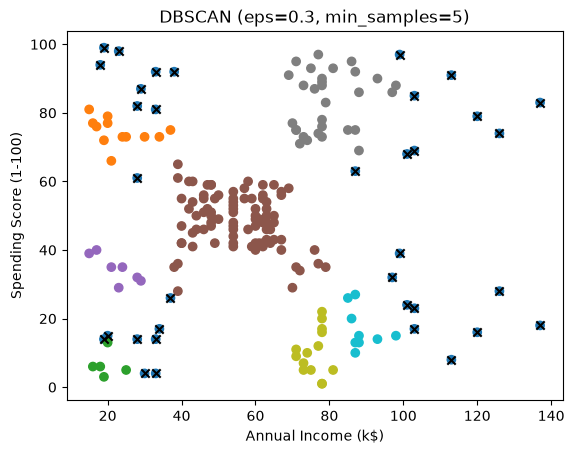

In [10]:
# Buat scatter plot hasil DBSCAN berdasarkan labels_dbscan.
# Gunakan X_scaled atau X untuk koordinat plot; untuk interpretasi, X (fitur asli)
# biasanya lebih mudah dipahami.
# Beri judul dan label sumbu yang jelas, serta pastikan noise dapat dibedakan.
def plot_cluster(labels, title):
    plt.scatter(X[cols[0]], X[cols[1]], c=labels, cmap='tab10')
    plt.scatter(X[cols[0]][labels == -1], X[cols[1]][labels == -1], c='black', marker='x', label='Noise')
    plt.xlabel(cols[0])
    plt.ylabel(cols[1])
    plt.title(title)
    plt.show()

plot_cluster(labels_dbscan, 'DBSCAN (eps=0.3, min_samples=5)')

In [11]:
# Coba beberapa kombinasi eps dan min_samples.
# Buat tabel ringkasan yang berisi eps, min_samples, jumlah cluster (tanpa noise),
# jumlah noise, dan Silhouette Score jika metrik tersebut valid.
# Hindari menghitung silhouette jika hasilnya hanya satu cluster atau semua titik noise.
hasil = []
for eps in [0.2, 0.3, 0.35, 0.4, 0.5]:
    for ms in [3, 5, 10]:
        lb = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
        mask = lb != -1
        k = len(set(lb[mask]))
        sil = silhouette_score(X_scaled[mask], lb[mask]) if k >= 2 else np.nan
        hasil.append([eps, ms, k, (~mask).sum(), sil])
pd.DataFrame(hasil, columns=['eps', 'min_samples', 'n_cluster', 'n_noise', 'silhouette'])

,eps,min_samples,n_cluster,n_noise,silhouette
0,0.20,3,13,44,0.469713
1,0.20,5,7,77,0.585613
2,0.20,10,1,129,NaN
3,0.30,3,9,14,0.472040
4,0.30,5,7,35,0.524328
5,0.30,10,4,88,0.607301
6,0.35,3,7,11,0.515389
7,0.35,5,6,23,0.557746
8,0.35,10,5,73,0.528808
9,0.40,3,4,10,0.395381


### Analisis DBSCAN

- Apa pengaruh kenaikan `eps` terhadap jumlah cluster dan noise?
- Apa pengaruh `min_samples`?
- Apakah ada kombinasi parameter yang menghasilkan satu cluster besar atau terlalu banyak noise?

**Jawaban:**
- Kenaikan `eps` membuat lingkungan tetangga makin luas sehingga noise berkurang dan cluster bergabung (eps=0.5, min_samples=5 → hanya 2 cluster, 8 noise).
- Kenaikan `min_samples` membuat syarat core point makin ketat sehingga noise bertambah dan cluster kecil hilang (eps=0.3: min_samples 3 → 14 noise, 10 → 88 noise).
- Ya. eps=0.2, min_samples=10 hanya menghasilkan 1 cluster dengan 129 noise (terlalu banyak noise), sedangkan eps=0.5 menggabungkan kelompok menjadi 2 cluster besar. Kombinasi eps=0.35, min_samples=5 dipilih karena seimbang (6 cluster, 23 noise, silhouette 0.558).

# 4. Eksperimen BIRCH

BIRCH (*Balanced Iterative Reducing and Clustering using Hierarchies*) membangun struktur pohon ringkasan cluster. Parameter `threshold` mengatur seberapa dekat titik harus berada agar dapat digabungkan dalam subcluster. `n_clusters` menentukan jumlah cluster akhir jika diberikan.

Berbeda dari DBSCAN, BIRCH tidak memberi label noise secara eksplisit.

In [12]:
# Latih model Birch pada X_scaled.
# Coba threshold awal, misalnya 0.5, dan n_clusters=5.
# Simpan label hasil clustering sebagai labels_birch.
# Catatan: jumlah cluster akhir dapat berubah sesuai parameter yang digunakan.
labels_birch = Birch(threshold=0.5, n_clusters=5).fit_predict(X_scaled)

In [13]:
# Tampilkan jumlah anggota setiap cluster BIRCH.
# Tampilkan juga jumlah cluster yang terbentuk.
print(pd.Series(labels_birch).value_counts().sort_index())
print('Jumlah cluster:', len(set(labels_birch)))

0     36
1    109
2      8
3     25
4     22
Name: count, dtype: int64
Jumlah cluster: 5


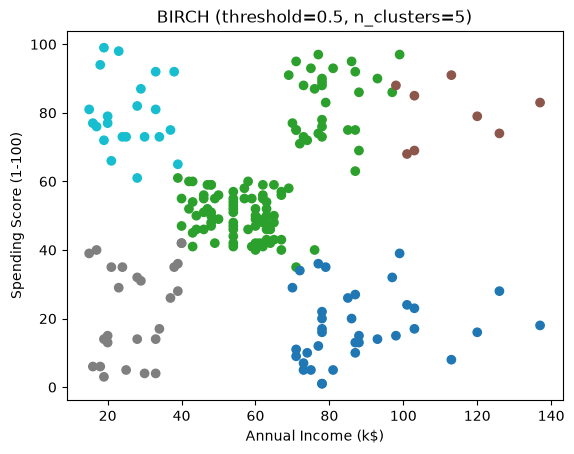

In [14]:
# Buat scatter plot hasil BIRCH pada ruang fitur asli X.
# Warnai titik berdasarkan labels_birch.
plot_cluster(labels_birch, 'BIRCH (threshold=0.5, n_clusters=5)')

In [15]:
# Bandingkan beberapa nilai threshold (misalnya 0.3, 0.5, 0.7, 1.0)
# dengan jumlah cluster akhir yang sama jika memungkinkan.
# Buat tabel berisi threshold, jumlah cluster, dan Silhouette Score bila valid.
hasil = []
for t in [0.3, 0.5, 0.7, 1.0]:
    for n in [5, None]:
        lb = Birch(threshold=t, n_clusters=n).fit_predict(X_scaled)
        k = len(set(lb))
        sil = silhouette_score(X_scaled, lb) if 1 < k < len(lb) else np.nan
        hasil.append([t, n, k, sil])
pd.DataFrame(hasil, columns=['threshold', 'n_clusters', 'n_cluster_akhir', 'silhouette'])

,threshold,n_clusters,n_cluster_akhir,silhouette
0,0.3,5.0,5,0.478062
1,0.3,NaN,23,0.414325
2,0.5,5.0,5,0.414450
3,0.5,NaN,10,0.477382
4,0.7,5.0,5,0.420676
5,0.7,NaN,6,0.486130
6,1.0,5.0,4,0.388557
7,1.0,NaN,4,0.388557


### Analisis BIRCH

- Apa yang terjadi pada jumlah cluster ketika `threshold` diperbesar?
- Apa perbedaan BIRCH dan DBSCAN dalam menangani titik yang berada jauh dari kelompok utama?
- Apakah hasil BIRCH berubah ketika `n_clusters` ditentukan?

**Jawaban:**
- Tanpa `n_clusters`, threshold makin besar membuat subcluster makin sedikit (0.3 → 23, 0.5 → 10, 0.7 → 6, 1.0 → 4 cluster).
- DBSCAN menandai titik jauh sebagai noise (-1), sedangkan BIRCH tetap memasukkan setiap titik ke cluster (contoh: 3 pelanggan berpenghasilan ~127 k$ menjadi cluster tersendiri atau ikut cluster terdekat).
- Ya. Dengan `n_clusters=5`, subcluster digabung kembali menjadi 5 cluster akhir, kecuali jika subcluster yang terbentuk lebih sedikit (threshold=1.0 hanya 4 cluster). Threshold=0.3 dengan n_clusters=5 memberi silhouette terbaik (0.478).

# 5. Eksperimen EM dengan Gaussian Mixture Model

Expectation-Maximization (EM) adalah algoritma iteratif untuk mengestimasi parameter model probabilistik. Dalam praktikum ini, EM digunakan untuk melatih **Gaussian Mixture Model (GMM)**.

GMM menganggap data berasal dari campuran beberapa distribusi Gaussian. Untuk setiap titik, GMM menghasilkan probabilitas keanggotaan pada setiap komponen, kemudian label cluster ditentukan dari komponen dengan probabilitas terbesar.

Parameter utama:
- `n_components`: jumlah distribusi Gaussian/cluster yang dimodelkan.
- `covariance_type`: bentuk matriks kovarians yang digunakan.
- `random_state`: agar hasil eksperimen dapat diulang.

In [16]:
# Latih GaussianMixture pada X_scaled menggunakan EM.
# Mulai dengan n_components=5, covariance_type='full', dan random_state=42.
# Simpan label hasil prediksi sebagai labels_gmm.
gmm = GaussianMixture(n_components=5, covariance_type='full', random_state=42).fit(X_scaled)
labels_gmm = gmm.predict(X_scaled)

In [17]:
# Tampilkan jumlah anggota setiap cluster GMM.
# Gunakan predict_proba untuk melihat probabilitas keanggotaan tiap titik.
# Tampilkan beberapa baris probabilitas dan periksa apakah ada titik dengan
# keanggotaan yang relatif tidak pasti.
print(pd.Series(labels_gmm).value_counts().sort_index())
proba = pd.DataFrame(gmm.predict_proba(X_scaled)).round(3)
display(proba.head())
print('Titik tidak pasti (max proba < 0.8):', (proba.max(axis=1) < 0.8).sum())

0    84
1    39
2    21
3    33
4    23
Name: count, dtype: int64


,0,1,2,3,4
0,0.0,0.0,0.001,0.0,0.999
1,0.0,0.0,1.000,0.0,0.000
2,0.0,0.0,0.000,0.0,1.000
3,0.0,0.0,1.000,0.0,0.000
4,0.0,0.0,0.002,0.0,0.998


Titik tidak pasti (max proba < 0.8): 6


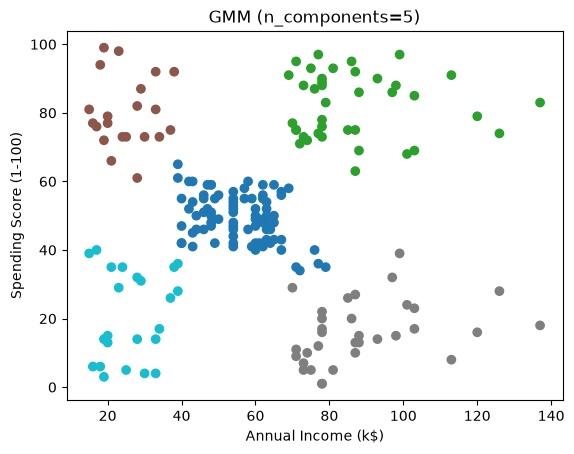

In [18]:
# Buat scatter plot hasil GMM pada ruang fitur asli X.
# Warnai titik berdasarkan labels_gmm.
plot_cluster(labels_gmm, 'GMM (n_components=5)')

In [19]:
# Bandingkan beberapa nilai n_components (misalnya 2 sampai 8).
# Catat Silhouette Score dan BIC untuk setiap model.
# BIC yang lebih rendah menunjukkan keseimbangan model dan kecocokan data yang lebih baik
# menurut kriteria BIC, tetapi tetap perlu dipertimbangkan bersama visualisasi dan konteks.
hasil = []
for n in range(2, 9):
    g = GaussianMixture(n_components=n, covariance_type='full', random_state=42).fit(X_scaled)
    hasil.append([n, silhouette_score(X_scaled, g.predict(X_scaled)), g.bic(X_scaled)])
pd.DataFrame(hasil, columns=['n_components', 'silhouette', 'BIC'])

,n_components,silhouette,BIC
0,2,0.379082,1153.904655
1,3,0.430190,1151.718274
2,4,0.413392,1103.790149
3,5,0.553689,1058.652252
4,6,0.516982,1074.682807
5,7,0.509057,1087.328517
6,8,0.430210,1102.370701


### Analisis EM/GMM

- Apa arti probabilitas keanggotaan yang dihasilkan GMM?
- Apa yang terjadi ketika `n_components` diubah?
- Mengapa jumlah cluster GMM perlu ditentukan sebelum model dilatih?
- Apakah model dengan Silhouette Score tertinggi juga memiliki BIC terendah?

**Jawaban:**
- Probabilitas keanggotaan menunjukkan seberapa besar kemungkinan suatu titik berasal dari tiap komponen Gaussian (soft clustering). Sebagian besar titik memiliki probabilitas ≈1, hanya 6 titik dengan probabilitas maksimum < 0.8 (berada di perbatasan cluster).
- `n_components` yang terlalu kecil menggabungkan kelompok berbeda, sedangkan yang terlalu besar memecah kelompok alami; silhouette dan BIC sama-sama membaik hingga 5 lalu memburuk.
- Karena EM mengestimasi parameter (mean, kovarians, bobot) untuk sejumlah komponen yang tetap, sehingga jumlah komponen harus ditentukan di awal.
- Ya, n_components=5 memiliki silhouette tertinggi (0.554) sekaligus BIC terendah (1058.7).

# 6. Evaluasi dan Perbandingan Model

Bandingkan model DBSCAN, BIRCH, dan GMM menggunakan:
- Jumlah cluster yang terbentuk.
- Jumlah titik noise, khusus untuk DBSCAN.
- Silhouette Score: semakin tinggi biasanya semakin baik.
- Davies-Bouldin Index: semakin rendah biasanya semakin baik.
- Calinski-Harabasz Score: semakin tinggi biasanya semakin baik.

Metrik internal perlu ditafsirkan dengan hati-hati. Untuk DBSCAN, keluarkan titik noise dari perhitungan metrik jika ingin menilai kualitas cluster yang terbentuk. Metrik tidak dapat dihitung secara bermakna jika hasilnya hanya satu cluster atau setiap titik menjadi cluster sendiri.

In [20]:
# Buat fungsi evaluasi yang menerima X_scaled dan label clustering.
# Untuk DBSCAN, hitung metrik pada titik non-noise saja.
# Pastikan metrik hanya dihitung jika terdapat setidaknya 2 cluster
# dan jumlah cluster lebih kecil daripada jumlah titik yang dievaluasi.
def evaluasi(X_scaled, labels):
    mask = labels != -1
    Xe, le = X_scaled[mask], labels[mask]
    k = len(set(le))
    if not 2 <= k < len(le):
        return k, (~mask).sum(), np.nan, np.nan, np.nan
    return k, (~mask).sum(), silhouette_score(Xe, le), davies_bouldin_score(Xe, le), calinski_harabasz_score(Xe, le)

In [21]:
# Evaluasi hasil terbaik dari DBSCAN, BIRCH, dan GMM.
# Sajikan ringkasan dalam satu DataFrame/tabel:
# model, jumlah cluster, jumlah noise, silhouette, Davies-Bouldin, Calinski-Harabasz.
# Untuk BIRCH dan GMM, jumlah noise dapat ditulis 0 atau N/A karena algoritma
# tersebut tidak menandai noise secara eksplisit.
labels_dbscan = DBSCAN(eps=0.35, min_samples=5).fit_predict(X_scaled)
labels_birch = Birch(threshold=0.3, n_clusters=5).fit_predict(X_scaled)
LABELS = {'DBSCAN': labels_dbscan, 'BIRCH': labels_birch, 'GMM': labels_gmm}
pd.DataFrame([[m, *evaluasi(X_scaled, lb)] for m, lb in LABELS.items()],
             columns=['model', 'n_cluster', 'n_noise', 'silhouette', 'davies_bouldin', 'calinski_harabasz'])

,model,n_cluster,n_noise,silhouette,davies_bouldin,calinski_harabasz
0,DBSCAN,6,23,0.557746,0.510621,245.355677
1,BIRCH,5,0,0.478062,0.647674,144.013475
2,GMM,5,0,0.553689,0.576010,244.940197


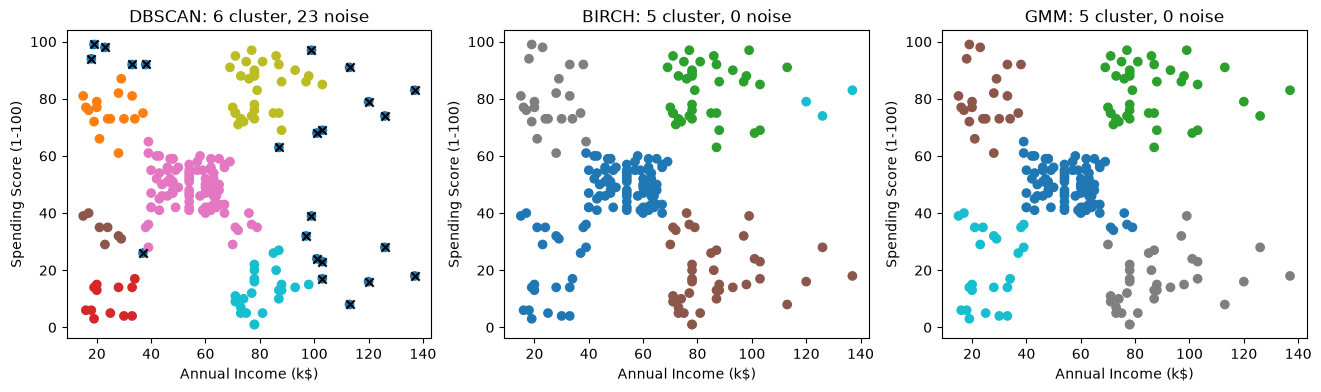

In [22]:
# Buat tiga scatter plot dalam satu baris subplot:
# DBSCAN, BIRCH, dan GMM.
# Gunakan koordinat dari fitur asli X dan warna berdasarkan label cluster.
# Beri judul yang menunjukkan algoritma dan jumlah cluster/noise.
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, (m, lb) in zip(ax, LABELS.items()):
    a.scatter(X[cols[0]], X[cols[1]], c=lb, cmap='tab10')
    a.scatter(X[cols[0]][lb == -1], X[cols[1]][lb == -1], c='black', marker='x')
    a.set_title(f'{m}: {len(set(lb) - {-1})} cluster, {(lb == -1).sum()} noise')
    a.set_xlabel(cols[0])
    a.set_ylabel(cols[1])
plt.show()

In [23]:
# Buat profil cluster pada fitur asli.
# Untuk setiap algoritma, tampilkan jumlah anggota serta median dan rata-rata
# Annual Income (k$) dan Spending Score (1-100) untuk setiap cluster.
# Untuk DBSCAN, analisis label -1 (noise) secara terpisah.
for m, lb in LABELS.items():
    print(m)
    display(X.assign(cluster=lb).groupby('cluster')[cols].agg(['count', 'median', 'mean']).round(1))

DBSCAN


Annual Income (k$)              Spending Score (1-100)             
                     count median  mean                  count median  mean
cluster                                                                    
-1                      23  101.0  89.3                     23   68.0  57.8
 0                      16   24.5  24.8                     16   75.5  75.4
 1                      12   22.5  24.6                     12    9.5   9.6
 2                       7   23.0  22.4                      7   35.0  34.4
 3                      88   54.0  55.2                     88   49.0  48.6
 4                      31   78.0  80.3                     31   86.0  83.2
 5                      23   78.0  81.0                     23   13.0  12.8

BIRCH


Annual Income (k$)               Spending Score (1-100)             
                     count median   mean                  count median  mean
cluster                                                                     
0                      101   50.0   48.2                    101   47.0  43.4
1                       36   78.0   83.1                     36   85.5  82.4
2                       38   80.0   87.0                     38   16.5  18.6
3                       22   24.5   25.7                     22   77.0  79.4
4                        3  126.0  127.7                      3   79.0  78.7

GMM


Annual Income (k$)              Spending Score (1-100)             
                     count median  mean                  count median  mean
cluster                                                                    
0                       84   55.5  55.6                     84   49.5  49.4
1                       39   79.0  86.5                     39   83.0  82.1
2                       21   24.0  25.1                     21   77.0  80.0
3                       33   86.0  88.8                     33   15.0  16.0
4                       23   25.0  26.3                     23   17.0  20.9

### Ringkasan Perbandingan

| Aspek | DBSCAN | BIRCH | EM/GMM |
|---|---|---|---|
| Perlu menentukan jumlah cluster di awal? | Tidak | Opsional (`n_clusters`) | Ya (`n_components`) |
| Dapat memberi label noise secara eksplisit? | Ya (label -1) | Tidak | Tidak (hanya probabilitas rendah) |
| Parameter yang paling memengaruhi hasil | `eps`, `min_samples` | `threshold`, `n_clusters` | `n_components`, `covariance_type` |
| Bentuk cluster yang dapat dimodelkan | Bentuk bebas (berbasis kepadatan) | Cenderung bulat/kompak | Elips (Gaussian) |
| Kelebihan | Mendeteksi noise, bentuk cluster bebas | Cepat dan hemat memori untuk data besar | Soft clustering, ada BIC untuk memilih jumlah cluster |
| Kekurangan | Sensitif parameter, sulit untuk kepadatan berbeda | Tidak mendeteksi noise, sensitif threshold | Jumlah cluster harus ditentukan, asumsi Gaussian |

# 7. Analisis

Jelaskan hasil eksperimen dengan merujuk pada output notebook kalian sendiri. Bahas poin-poin berikut:

1. Mengapa fitur perlu di-scaling sebelum clustering?
2. Bagaimana perubahan parameter DBSCAN memengaruhi jumlah cluster dan noise?
3. Bagaimana parameter `threshold` dan `n_clusters` memengaruhi BIRCH?
4. Apa makna probabilitas keanggotaan GMM dan bagaimana EM menggunakannya?
5. Model mana yang paling mudah diinterpretasikan pada dataset ini? Jelaskan alasannya.
6. Apakah metrik evaluasi menunjukkan algoritma terbaik yang sama? Jika berbeda, apa kemungkinan penyebabnya?
7. Jelaskan karakteristik cluster berdasarkan median pendapatan dan spending score. Berikan nama deskriptif pada cluster jika memungkinkan.
8. Apa keterbatasan penggunaan hanya dua fitur dan dataset pelanggan yang berukuran kecil?

**Jawaban:**
1. Algoritma berbasis jarak (DBSCAN, BIRCH) dan GMM sensitif terhadap skala. Tanpa scaling, fitur dengan rentang lebih besar (Income 15–137) akan mendominasi jarak dibanding Spending Score (1–99).
2. `eps` naik → noise turun dan cluster bergabung; `min_samples` naik → noise naik dan cluster kecil hilang. Pada eksperimen, jumlah cluster berkisar 1–13 dan noise 7–129 tergantung kombinasi parameter.
3. `threshold` kecil menghasilkan banyak subcluster (23 pada 0.3), threshold besar menghasilkan sedikit (4 pada 1.0). `n_clusters` menggabungkan subcluster menjadi jumlah akhir yang ditentukan.
4. Probabilitas keanggotaan adalah responsibility tiap komponen terhadap setiap titik. Pada E-step, EM menghitung probabilitas ini; pada M-step, probabilitas tersebut dipakai sebagai bobot untuk memperbarui mean, kovarians, dan bobot komponen hingga konvergen.
5. GMM dengan 5 cluster paling mudah diinterpretasikan karena kelima cluster sesuai dengan 5 kelompok yang terlihat pada scatter plot, tanpa noise, dan didukung BIC terendah.
6. Hampir sama: DBSCAN sedikit unggul (silhouette 0.558, DBI 0.511, CH 245.4) dibanding GMM (0.554, 0.576, 244.9), sedangkan BIRCH terendah. Keunggulan DBSCAN sebagian karena 23 titik noise (titik sulit) dikeluarkan dari perhitungan metrik, sehingga tidak sepenuhnya adil.
7. Berdasarkan median GMM: cluster 0 (Income 55.5, Score 49.5) *Standar/Rata-rata*; cluster 1 (79, 83) *Target Utama – kaya & boros*; cluster 2 (24, 77) *Hemat penghasilan tapi boros*; cluster 3 (86, 15) *Kaya tapi hemat*; cluster 4 (25, 17) *Hemat/berhati-hati*.
8. Dua fitur mengabaikan informasi lain (usia, gender) yang mungkin penting untuk segmentasi. Dengan hanya 200 data, hasil sensitif terhadap parameter dan outlier, serta kurang dapat digeneralisasi ke populasi pelanggan yang lebih luas.

# 8. Kesimpulan dan Saran

Tuliskan kesimpulan berdasarkan eksperimen:
- Algoritma mana yang memberikan hasil paling berguna untuk dataset ini?
- Parameter apa yang dipilih dan mengapa?
- Apa perbedaan utama DBSCAN, BIRCH, dan EM/GMM yang kalian pelajari?
- Eksperimen lanjutan apa yang dapat dilakukan?

Pastikan kesimpulan didasarkan pada hasil eksperimen sendiri, bukan hanya teori.

**Jawaban:**
- GMM memberikan hasil paling berguna: 5 segmen yang jelas, semua pelanggan terlabel, dan metrik hampir setara dengan DBSCAN terbaik.
- Parameter terpilih: GMM `n_components=5` (silhouette tertinggi & BIC terendah), DBSCAN `eps=0.35, min_samples=5` (keseimbangan cluster dan noise), BIRCH `threshold=0.3, n_clusters=5` (silhouette tertinggi di antara variasi BIRCH).
- DBSCAN berbasis kepadatan dan dapat mendeteksi noise; BIRCH merangkum data dalam pohon CF sehingga efisien; GMM bersifat probabilistik dan memberi soft assignment melalui EM.
- Eksperimen lanjutan: menambah fitur `Age`, mencoba `covariance_type` lain pada GMM, memilih `eps` dengan k-distance plot, serta menguji pada dataset yang lebih besar.

## Referensi

- Dataset: [Mall Customer Segmentation Data, Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data)
- Dokumentasi DBSCAN: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html)
- Dokumentasi BIRCH: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.Birch.html)
- Dokumentasi Gaussian Mixture: [scikit-learn](https://scikit-learn.org/stable/modules/mixture.html#gaussian-mixture)